In [1]:
!pip install torch torchvision

Defaulting to user installation because normal site-packages is not writeable


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.8.0+cpu
Torchvision: 0.23.0+cpu


MNIST Dataset Loaded Successfully!
Training samples: 60000
Testing samples: 10000


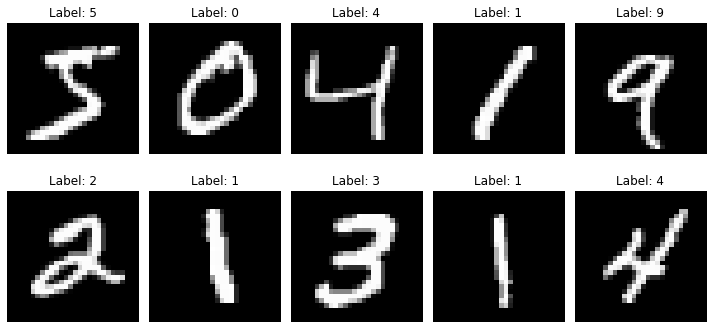

In [3]:
# Cell 2: Load and Visualize MNIST Dataset

import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Load training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load test dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("MNIST Dataset Loaded Successfully!")
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Cell 3: Create DataLoaders

from torch.utils.data import DataLoader

# Batch size
batch_size = 64

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")
print("Batch size:", batch_size)

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

DataLoaders created successfully!
Batch size: 64
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


In [5]:
# Cell 4: Define MLP Model

import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )
    
    def forward(self, x):
        return self.network(x)


# Create model
mlp_model = MLP()

print(mlp_model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [6]:
# Cell 5: Loss Function and Optimizer

import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(mlp_model.parameters(), lr=0.001)

print("Loss function and optimizer created!")

Loss function and optimizer created!


In [7]:
# Cell 6: Train the MLP

import time

def train_model(model, train_loader, criterion, optimizer, epochs=5):
    
    model.train()
    
    loss_history = []
    accuracy_history = []
    
    start_time = time.time()
    
    for epoch in range(epochs):
        
        running_loss = 0.0
        correct = 0
        total = 0
        
        for images, labels in train_loader:
            
            # 1. Clear old gradients
            optimizer.zero_grad()
            
            # 2. Forward pass - make predictions
            outputs = model(images)
            
            # 3. Calculate loss
            loss = criterion(outputs, labels)
            
            # 4. Backpropagation
            loss.backward()
            
            # 5. Update weights
            optimizer.step()
            
            # Store loss
            running_loss += loss.item()
            
            # Calculate accuracy
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        
        loss_history.append(epoch_loss)
        accuracy_history.append(epoch_accuracy)
        
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )
    
    training_time = time.time() - start_time
    
    return loss_history, accuracy_history, training_time

In [8]:
# Train MLP

mlp_loss, mlp_accuracy, mlp_time = train_model(
    mlp_model,
    train_loader,
    criterion,
    optimizer,
    epochs=5
)

print(f"\nMLP Training Time: {mlp_time:.2f} seconds")

Epoch [1/5] Loss: 0.3441 Accuracy: 90.39%
Epoch [2/5] Loss: 0.1407 Accuracy: 95.84%
Epoch [3/5] Loss: 0.0971 Accuracy: 97.03%
Epoch [4/5] Loss: 0.0723 Accuracy: 97.78%
Epoch [5/5] Loss: 0.0584 Accuracy: 98.17%

MLP Training Time: 205.24 seconds


In [9]:
# Cell 7: Evaluate MLP on Test Dataset

def evaluate_model(model, test_loader):
    
    model.eval()
    
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            
            outputs = model(images)
            
            _, predicted = torch.max(outputs, 1)
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    accuracy = 100 * correct / total
    
    return accuracy


mlp_test_accuracy = evaluate_model(mlp_model, test_loader)

print(f"MLP Test Accuracy: {mlp_test_accuracy:.2f}%")

MLP Test Accuracy: 97.50%
